In [9]:
# Importing necessary packages
import numpy as np # Supports arrays, matrices, etc. and the mathematical functions to operate them
import matplotlib.pyplot as plt # For creating plots
import pandas as pd # Data handling 
import pyp2options # Custom library --> don't know what it does yet
from astropy.coordinates import SkyCoord # Represents and converts astronomical coordinates
import astropy.units as u # Handles physical units
import scipy.optimize as spopt # Contains optimization algorithms
import sys 

from matplotlib.backends.backend_pdf import PdfPages # Saves multiple matplotlib figures into a single PDF file

In [10]:
# Required arguments
field = 'MISHAPS_F1_DITH0'
chip = 'N10'
mag = 'r' # Magnitude
color1 = 'r'  
color2 = 'z'  
fc = f"{field}_{chip}" # # Combined field_chip string
    
#g-i values for CMD analysis
colorcut = 1.06
magcut = 17.3
color_min=0.0
color_max=2.0
msto_shift=3.5 # Main Sequence Turn-Off shift value

# Adjusts cut values based on filter choices
if color2=="z" and color1=="r":
    colorcut=0.46
    color_max=1.0
    msto_shift=3.0 
interactive = False # Default = False, determines whether to have interactive plots

# Check if interactive plotting is enabled
if len(sys.argv)>=6:
    interactive=True

# Optional override for color cut
if len(sys.argv)>=7:
    colorcut = float(sys.argv[6])
    print("colorcut =",colorcut)

# Optional override for magnitude cut
if len(sys.argv)>=8:
    magcut = float(sys.argv[7])
    print("magcut =",magcut)

print("mag color1 color2",mag,color1,color2)

# Optional RA/Dec region cuts (positional filtering)
ra_min=-1 # All four of these default to -1; min and max RA and Dec to use if doing a position cut
ra_max=-1
dec_min=-1
dec_max=-1
poscut=False # Default = False, whether to do a position cut
if len(sys.argv)>=9:
    ra_min=float(sys.argv[8])
    ra_max=float(sys.argv[9])
    dec_min=float(sys.argv[10])
    dec_max=float(sys.argv[11])
    poscut=True

mag color1 color2 r r z


In [11]:
options = pyp2options.pip2options('/home/bernthold.17/SURP2025/rcfit/')

qflag_mag=options['cmdq-' + mag]-1 # Quality flag column for 'mag' band
qflag_c1=options['cmdq-' + color1]-1 # Quality flag column for 'c1' band
qflag_c2=options['cmdq-' + color2]-1 # Quality flag column for 'c2' band

mag_col=options['cmdm-' + mag]-1 # Magnitude column in cmd file for 'mag' band
c1_col=options['cmdm-' + color1]-1 # Magnitude column in cmd file for 'c1' band
c2_col=options['cmdm-' + color2]-1 # Magnitude column in cmd file for 'c2' band

ra_col=1 # RA column
dec_col=2 # Dec column


refdir = options['refdir'] 
#refdir = '/Users/penny/mishaps/scratch/redclump'
#refdir = '/Volumes/olympus/mishaps/ref/Jan2022'
refdir = '/home/bernthold.17/SURP2025/rcfit/'

# This has something to do with the image size down from 2048x4096 to 512x512
nx=4
ny=8
size=2048.0/nx

/home/bernthold.17/SURP2025/rcfit/pyp2options.py:12: ParserWarning: Skipping line 65: expected 2 fields, saw 5
Skipping line 68: expected 2 fields, saw 5
Skipping line 71: expected 2 fields, saw 5
Skipping line 74: expected 2 fields, saw 5
Skipping line 80: expected 2 fields, saw 5
Skipping line 83: expected 2 fields, saw 5

  df = pd.read_csv(pipedir + '/pip2options.sh',sep='=',header=None,comment="#",on_bad_lines=on_bad_lines)


In [14]:
# l - galactic longitude, b - galactic latitude, our view of a star relative to the galactic center (0,0)
def rccolor(l,b):
    # Function for getting the known color of the red clump at a given l and b coordinate
    # Gives the g, r, i, and z photometry for the red clump, RGB branch, and AGB branch;
    # the distance to the red clump at that l and b; and the distance modulus mu
    # mu = m - M = 5*log10(d) - 5; https://en.wikipedia.org/wiki/Distance_modulus
    
    I0 = 14.3955 - 0.0239*l + 0.0122*np.abs(b) #Dereddened I mag of red clump
    I = np.array([I0,I0+0.737,I0-1.07]) #of RC, RGBB & AGBB
    dmod = I-14.3955 + 5.0*np.log10(8178.0)-5.0 #Distance modulus of bar density peak
    d = 10**(0.2*(dmod+5)) #distance
    V = 1.060+I            #V mag of clump (note RGBB and AGBB V will be wrong)
    
    # Use the relations between UBVRI and SDSS ugriz to get the griz mags
    gs = V+0.553           #g sdss                        
    rs = V-0.327           #r sdss
    i_s = V-0.600          #i sdss

    gmi = gs-i_s           #(g-i) sdss
    
    # rgbb = red giant branch, agbb = asymptotic giant branch
    rgbb_rs = 1.060+I+0.737-0.327
    agbb_rs = 1.060+I-1.070-0.327
    rgbb_gmi = 0.553+0.600-0.06
    agbb_gmi = 0.553+0.600+0.2

    print("rs",rs,rgbb_rs,agbb_rs)
    print("gmi",gmi,rgbb_gmi,agbb_gmi)
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0,10):                                                  
        gpmgs = -0.01808 -0.13595*gmi +0.01941*gmi**2 -0.00183*gmi**3
        rpmrs = -0.01836 -0.03577*gmi +0.02612*gmi**2 -0.00558*gmi**3
        ipmis = 0.01170 -0.00400*gmi +0.00066*gmi**2 -0.00058*gmi**3
        gp=gs+gpmgs #g panstarrs
        rp=rs+rpmrs #r panstarrs
        ip=i_s+ipmis #i panstarrs
        gmi=gp-ip #gmi panstarrs
        rmi=rp-ip #rmi panstarrs
        imz=0.234625+0.211715*(gmi-1.25) #i-z panstarrs
        rmz=rmi+imz #r-z panstarrs
        zp = rp-rmz #z panstarrs

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":gp[0],"clump-r":rp[0],"clump-i":ip[0],"clump-z":zp[0],
           "rgbb-g":gp[1], "rgbb-r":rp[1], "rgbb-i":ip[1], "rgbb-z":zp[1],
           "agbb-g":gp[2], "agbb-r":rp[2], "agbb-i":ip[2], "agbb-z":zp[2],
           "distance":d[0], "dmod":dmod[0]}

        
        

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

def rcmodel(x,A,B,rcmag,Nrc,src):
    #print(zrc,zrc+rgbbz0,zrc+agbbz0)
    return A*np.exp(B*(x-rcmag)) + \
           Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-rcmag)**2/src**2) + \
           0.201*Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-(rcmag+rgbbmag0))**2/src**2) + \
           0.028*Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-(rcmag+agbbmag0))**2/src**2)

def cgauss(x,Nrc,crc,sc):
    return Nrc/(np.sqrt(2*np.pi*sc**2))*np.exp(-0.5*(x-crc)**2/sc**2)




data = pd.read_csv('/home/bernthold.17/SURP2025/Data_Files/MISHAPS_F1_DITH0_N10.cmd.calibrate_ps',header=None,sep='\s+')

# Create header titles for every column in the file
cmd_labels = ['ID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'mis_z', 'mis_z_err', 'Sky_z', 'qflag_z', '?1z', '?2z',
       'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'mis_r', 'mis_r_err', 'Sky_r', 'qflag_r', '?1r', '?2r',
       'RA_u', 'Dec_u', 'ID_u', 'X_u', 'Y_u', 'mis_u', 'mis_u_err', 'Sky_u', 'qflag_u', '?1u', '?2u',
       'RA_g', 'Dec_g', 'ID_g', 'X_g', 'Y_g', 'mis_g', 'mis_g_err', 'Sky_g', 'qflag_g', '?1g', '?2g',
       'RA_i', 'Dec_i', 'ID_i', 'X_i', 'Y_i', 'mis_i', 'mis_i_err', 'Sky_i', 'qflag_i', '?1i', '?2i',
       'RA_Y', 'Dec_Y', 'ID_Y', 'X_Y', 'Y_Y', 'mis_Y', 'mis_Y_err', 'Sky_Y', 'qflag_Y', '?1Y', '?2Y']
              
# Apply those header titles to the file
data.columns = cmd_labels

In [16]:
print(data.shape)
#print(cmd.iloc[:,qrcol],cmd.iloc[:,qzcol])
cmd = data[(data.iloc[:,qflag_c1]==1) & (data.iloc[:,qflag_c2]==1)]

# If you've given it an explicit position cut, use those values. Else use the min and max RA and Dec from the data
if poscut==True:
    cmd = cmd[(cmd.iloc[:,ra_col]>=ra_min) & (cmd.iloc[:,ra_col]<ra_max) & (cmd.iloc[:,dec_col]>=dec_min) & (cmd.iloc[:,dec_col]<dec_max)]
else:
    ra_min = np.nanmin(cmd.iloc[:,ra_col])
    ra_max = np.nanmax(cmd.iloc[:,ra_col])
    dec_min = np.nanmin(cmd.iloc[:,dec_col])
    dec_max = np.nanmax(cmd.iloc[:,dec_col])
print(cmd.shape)

(101166, 67)
(34630, 67)


In [17]:
# Get the mean RA and Dec
ra = np.nanmean(cmd.iloc[:,1])
dec = np.nanmean(cmd.iloc[:,2])

# Get l and b coordinates
coords = SkyCoord(ra,dec,frame='icrs',unit=u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
print(l,b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
red_clump = rccolor(l,b)

clumpmag0 = red_clump["clump-"+mag]
rgbbmag0 = red_clump["rgbb-"+mag]
agbbmag0 = red_clump["agbb-"+mag]

4.835380350737622 -7.9030828497424155
rs [15.10935202 15.84635202 14.03935202] [15.84635202 16.58335202 14.77635202] [14.03935202 14.77635202 12.96935202]
gmi [1.153 1.153 1.153] 1.093 1.353


In [7]:
print(red_clump["clump-"+mag],red_clump["dmod"],red_clump["distance"]) # mag = PanSTARRS mag ,dmod = distance modulus, distance (pc)
print(red_clump["clump-r"]-red_clump["clump-z"],red_clump["clump-g"]-red_clump["clump-i"]) # Colors 
print(mag+"0-clump,rgbb,agbb",red_clump["clump-"+mag],red_clump["rgbb-"+mag],red_clump["agbb-"+mag])

15.075760459462273 14.544087551475812 8106.20365163474
0.415050956235401 1.0079866656149221
r0-clump,rgbb,agbb 15.075760459462273 15.812760459462273 14.005760459462273


(1529, 67)


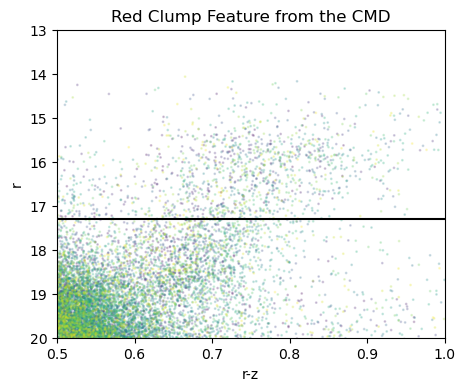

In [14]:
froot = '%s_%s.%s_%s-%s' % (field,chip,mag,c1,c2)
fpfile = open(froot + '.fpext.txt','a')

# Filter for the giants
giants = cmd[(cmd.iloc[:,mcol]<magcut) & (cmd.iloc[:,c1col]-cmd.iloc[:,c2col]>colorcut)]
print(giants.shape)

with PdfPages(froot+".pdf") as pdf:
    
    # This one just zooms in on the red clump portion of the CMD
    plt.figure(figsize =(5, 4))
    plt.tight_layout()
    # Plots the CMD color-coded by RA
    plt.scatter(cmd.iloc[:,c1col]-cmd.iloc[:,c2col],cmd.iloc[:,mcol],c=cmd.iloc[:,1],s=1,alpha=0.2,rasterized=True)
    
    # Plots the black line that shows the magnitude cut
    plt.plot([colorcut,colorcut,cmax],[13.0,magcut,magcut],'k-')
    plt.xlim(0.5,cmax)
    plt.ylim(20,13)
    
    if interactive==True:
        plt.ion()
        plt.show()
        cont = input("Type y to continue: ")
        if not (cont=="y" or cont=="Y"):
            sys.exit()
    plt.title('Red Clump Feature from the CMD')
    plt.xlabel('%s-%s' % (c1,c2))
    plt.ylabel(mag)
    
    plt.show()
#pdf.savefig()

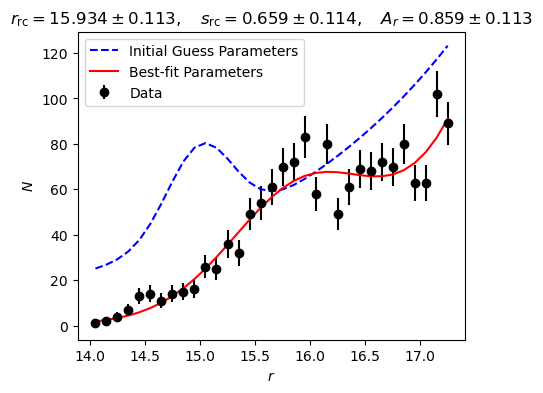

In [16]:
# Bins the magnitudes of the giants, be is bin edges
hist,be = np.histogram(giants.iloc[:,mcol],range=(magcut-4.0,magcut),bins=40,density=False)
bc = 0.5*(be[0:-1]+be[1:]) # Calculates bin centers from the bin edges

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask = (hist>0)
hist=hist[mask]
bc=bc[mask]

plt.figure(figsize=(5,4))
plt.tight_layout()
plt.errorbar(bc,hist,yerr=np.sqrt(hist),fmt='ko', label = 'Data') # Plot the histogram as points

guess = [40.0,0.5,15.0,30.0,0.3] # Initial guess for the curve fit

# use curve fit to try fitting the histogram data to the rcmodel function
# first argument is the function, second is the bin centers, third is the histogram values
# p0 is your initial guess for the parameters
# sigma is the uncertainty, the square root of the histogram is a close enough approximation
par,cov = spopt.curve_fit(rcmodel,bc,hist,p0=guess,sigma=np.sqrt(hist))

# par an array of the best-fit parameters, this sets each parameter to its own variable
# cov is the array of errors from the fit, I think technically as a covariance matrix
A,B,magrc,Nrc,src = par

# Plot your initial guess in blue and the best fit in red
plt.plot(bc,rcmodel(bc,*guess),'b--', label = 'Initial Guess Parameters')
plt.plot(bc,rcmodel(bc,*par),'r-', label = 'Best-fit Parameters')

plt.xlabel(r'$%s$' % (mag))
plt.ylabel(r'$N$')

plt.title(r'$%s_{\rm rc}=%6.3f\pm%5.3f,\quad s_{\rm rc}=%6.3f\pm%5.3f,' \
              '\quad A_%s=%5.3f\pm%5.3f$' % (mag, magrc, np.sqrt(cov[2,2]), src, np.sqrt(cov[4,4]),
                                             mag, magrc-clumpmag0, np.sqrt(cov[2,2])))
plt.legend(loc='best')
plt.show()

#pdf.savefig()

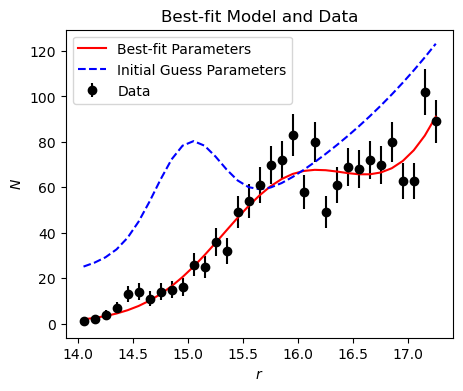

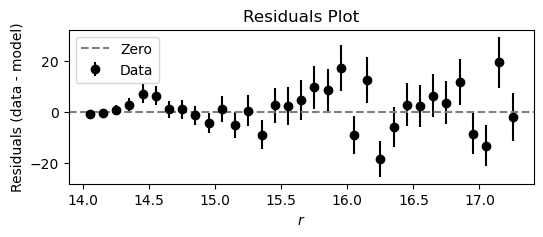

In [19]:
# Compute residuals
model_vals = rcmodel(bc, *par)
residuals = hist - model_vals

# Plot data and best-fit model
plt.figure(figsize=(5, 4))
plt.tight_layout()

plt.errorbar(bc, hist, yerr=np.sqrt(hist), fmt='ko', label='Data')
plt.plot(bc, rcmodel(bc, *par), 'r-', label='Best-fit Parameters')
plt.plot(bc, rcmodel(bc, *guess), 'b--', label='Initial Guess Parameters')

plt.title('Best-fit Model and Data')
plt.xlabel(r'$%s$' % (mag))
plt.ylabel(r'$N$')

plt.legend(loc = 'best')
plt.show()

# Plot residuals
plt.figure(figsize=(6, 2))
plt.tight_layout()

plt.errorbar(bc, residuals, yerr=np.sqrt(hist), fmt='ko', label = 'Data')
plt.axhline(0, color='gray', linestyle='--', label = 'Zero')

plt.xlabel(r'$%s$' % (mag))
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

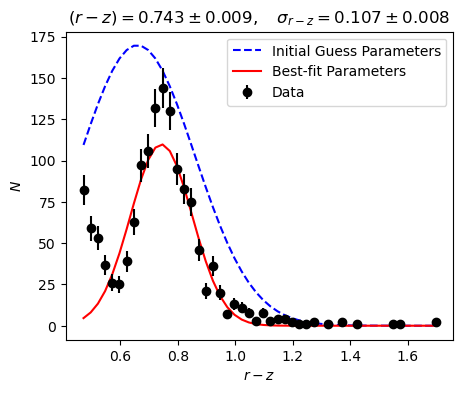

In [20]:
# From the giants, select only the red clump and repeat the fitting process from above
clumponly = giants[np.abs(giants.iloc[:,mcol]-magrc)<2*src]
hist2,be2 = np.histogram(clumponly.iloc[:,c1col]-clumponly.iloc[:,c2col],range=(colorcut,colorcut+1.5),bins=60,density=False)
bc2 = 0.5*(be2[0:-1]+be2[1:])

hist2mask = (hist2>0)
hist2 = hist2[hist2mask]
bc2=bc2[hist2mask]

guess2 = [par[3]+0.0,colorcut+0.2,0.2]

par2,cov2 = spopt.curve_fit(cgauss,bc2,hist2,p0=guess2,sigma=np.sqrt(hist2))

plt.figure(figsize = (5,4))
plt.tight_layout()

plt.plot(bc2,cgauss(bc2,*guess2),'b--', label = 'Initial Guess Parameters')
plt.plot(bc2,cgauss(bc2,*par2),'r-', label = 'Best-fit Parameters')
plt.errorbar(bc2,hist2,yerr=np.sqrt(hist2),fmt='ko', label = 'Data')

plt.title(r'$(%s-%s)=%6.3f\pm%5.3f,\quad \sigma_{%s-%s}=%6.3f\pm%5.3f$' % (c1,c2,par2[1],np.sqrt(cov2[1,1]),c1,c2,par2[2],np.sqrt(cov2[2,2])))
plt.xlabel(r'$%s-%s$' % (c1,c2))
plt.ylabel(r'$N$')

plt.legend(loc='best')
plt.show()
    
#pdf.savefig()

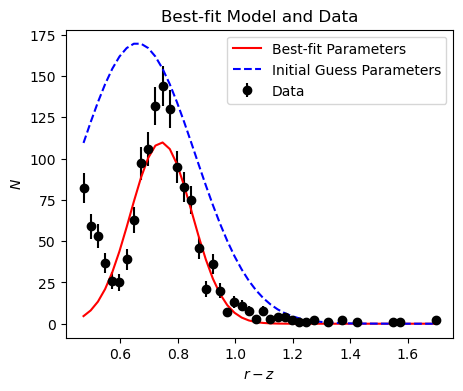

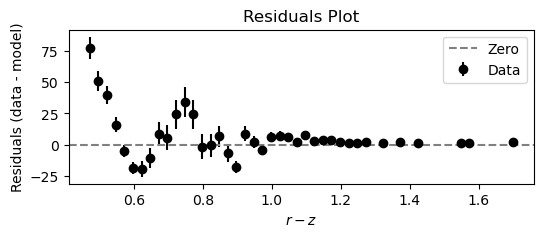

In [21]:
# Compute residuals
model_vals2 = cgauss(bc2, *par2)
residuals2 = hist2 - model_vals2

# Plot data and best-fit model
plt.figure(figsize=(5, 4))
plt.tight_layout()

plt.errorbar(bc2, hist2, yerr=np.sqrt(hist2), fmt='ko', label='Data')
plt.plot(bc2, cgauss(bc2, *par2), 'r-', label='Best-fit Parameters')
plt.plot(bc2, cgauss(bc2, *guess2), 'b--', label='Initial Guess Parameters')

plt.xlabel(r'$%s-%s$' % (c1, c2))
plt.ylabel(r'$N$')
plt.title('Best-fit Model and Data')

plt.legend(loc = 'best')
plt.show()

# Plot residuals
plt.figure(figsize=(6, 2))
plt.tight_layout()

plt.errorbar(bc2, residuals2, yerr=np.sqrt(hist2), fmt='ko', label = 'Data')
plt.axhline(0, color='gray', linestyle='--', label = 'Zero')

plt.xlabel(r'$%s-%s$' % (c1, c2))
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

In [10]:
# Print what you have so far + write it to a file
print('%s_rc = %6.3f +/- %5.3f,   src = %6.3f +/- %5.3f,   A_%s = %5.3f +/- %5.3f' 
      %(mag,par[2],np.sqrt(cov[2,2]),par[4],np.sqrt(cov[4,4]),mag,par[2]-clump["clump-"+mag],np.sqrt(cov[2,2])))
# r_rc = average r mag, s_rc = standard deviation 
# covariance matrix gives the errors

r_rc = 15.934 +/- 0.113,   src =  0.659 +/- 0.114,   A_r = 0.859 +/- 0.113


In [13]:
magrc = par[2]
Amag = magrc-clump["clump-"+mag]

colorrc = np.nanmedian(clumponly.iloc[:,c1col]-clumponly.iloc[:,c2col])
colorrc = par2[1]
Ecolor = colorrc-(clump["clump-"+c1]-clump["clump-"+c2])
tot2sel = Amag/Ecolor # ratio of extinction over color excess 
print('E(%s-%s) ='%(c1,c2),Ecolor,'  Tot/Sel =',tot2sel)

E(r-z) = 0.32799532427470834   Tot/Sel = 2.617563617484719


In [14]:
fpfile.write("#RA Dec l b A" + mag + " A"+c1 + " E("+c1+"-"+c2+")" + " A"+c1+"/E("+c1+"-"+c2+") distance RAmin RAmax Decmin Decmax\n")
fpfile.write("%9.5f %8.5f %g %g %g %g %g %g %g %g %g %g %g\n" % (a,d,l,b,Amag,Amag+Ecolor,Ecolor,tot2sel,clump["distance"],amin,amax,dmin,dmax))
RoA = tot2sel/Amag
fpfile.write("%9.5f %8.5f %g %g %g %g %g %g %g %g %g %g %g\n" % (0,0,0,0,np.sqrt(cov[2,2]),np.sqrt(cov[2,2]+cov2[2,2]),np.sqrt(cov2[2,2]),tot2sel*np.sqrt((cov[2,2])/Amag**2+cov2[2,2]/Ecolor**2),0,0,0,0,0))
fpfile.close()

Text(0, 0.5, '$r-z$')

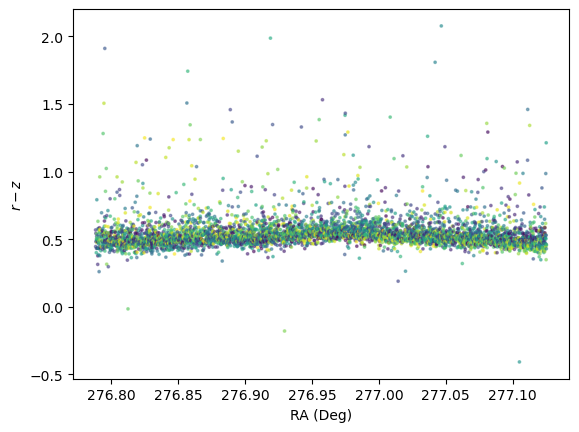

In [15]:
medcolor = colorrc-(clump["clump-"+c1]-clump["clump-"+c2])

# Select the main sequence turnoff (MSTO) + plot as a function of RA
#msto = cmd[(cmd.iloc[:,zcol]>=zcut+2.0) & (cmd.iloc[:,zcol]<zcut+2.0+0.5)]
msto = cmd[(cmd.iloc[:,mcol]>=magrc+3.5) & (cmd.iloc[:,mcol]<magrc+3.5+0.5)]

med_msto_color = np.nanmedian(msto.iloc[:,c1col]-msto.iloc[:,c2col])

plt.figure()
# Plot MSTO color as function of RA, color code by Dec
plt.scatter(msto.iloc[:,1],msto.iloc[:,c1col]-msto.iloc[:,c2col],c=msto.iloc[:,2],s=3,alpha=0.5)
plt.xlabel('RA (Deg)')
plt.ylabel(r'$%s-%s$' % (c1,c2))
#plt.ylim([0.25,0.75])
#plt.ylim([0.5,1.5])
#pdf.savefig()

Text(0, 0.5, '$r$')

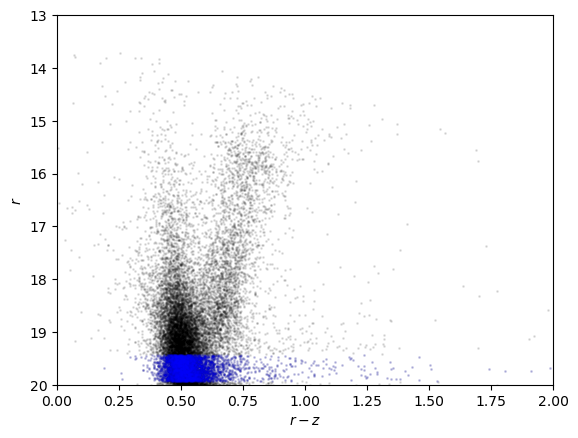

In [16]:
# Plot color-magnitude diagram with the MSTO highlighted
plt.figure()
plt.plot(cmd.iloc[:,c1col]-cmd.iloc[:,c2col],cmd.iloc[:,mcol],'ko',ms=1,alpha=0.1,rasterized=True)
plt.plot(msto.iloc[:,c1col]-msto.iloc[:,c2col],msto.iloc[:,mcol],'bo',ms=1,alpha=0.1,rasterized=True)
plt.xlim([0,2])
plt.ylim([20,13])
plt.xlabel(r'$%s-%s$' % (c1,c2))
plt.ylabel(r'$%s$' % (mag))
#pdf.savefig()

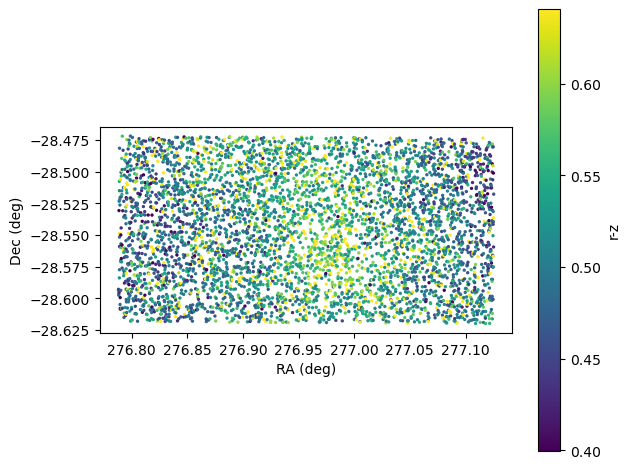

In [17]:
# Plots the color of the msto across the chip in RA and Dec. Color coded by 
 #the median color +/- the standard deviation of the color
plt.figure()
cmed = np.nanmedian(msto.iloc[:,c1col]-msto.iloc[:,c2col])
cstd = np.nanstd(msto.iloc[:,c1col]-msto.iloc[:,c2col])
    
    
plt.scatter(msto.iloc[:,1],msto.iloc[:,2],c=msto.iloc[:,c1col]-msto.iloc[:,c2col],s=2,vmin=cmed-cstd,vmax=cmed+cstd,rasterized=True)
cbar = plt.colorbar()
cbar.set_label('%s-%s' % (c1,c2))
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.gca().set_aspect(1.0/np.cos(d*np.pi/180.0))
plt.tight_layout()
#pdf.savefig()

In [18]:
print("RA (min med max):",amin,a,amax)
print("Dec (min med max):",dmin,d,dmax)
print("colorcut magcut:",colorcut,magcut)

RA (min med max): 276.788095 276.95672744421023 277.125526
Dec (min med max): -28.6199226 -28.545947733803064 -28.4719451
colorcut magcut: 0.46 17.3


In [41]:
#Algorithm
    #1. Estimate rRC and (r-z)RC to get initial estimate of A_r, E(r-z)
    #2. Select MSTO stars, compute median r-z in 512x512 square
    #3. Estimate Delta E(r-z) and Delta A_r from 512x512 square relative to whole chip
    #4. Correct stars to whole chip median reddening and extinction
    #5. Estimate rRC and (r-z)RC to get estimate of A_r, E(r-z)
    #6. Repeat steps 2-6 until convergence